# 01 Explore the data

What this notebook checks before any model is trained:

- how many essays there are, and how many are AI-generated
- how the essays spread over topics
- that label 1 really means AI (a sanity check)
- how long the essays are, and how many are too long for the transformers

Run `uv run python -m essaydetect.data` first, so the splits exist.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from essaydetect.data import LABEL_COL, SOURCE_COL, TEXT_COL, TOPIC_COL, load_split

# VS Code runs notebooks from the notebooks/ folder, so step up to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# The three parts of the random split together are the whole cleaned dataset.
df = pd.concat(load_split("random", ROOT / "data/splits").values(), ignore_index=True)
print(f"{len(df):,} essays")
df.head()

44,864 essays


,id,text,label,prompt_name,source
0,37292,"Yes, I agree that home schooling is a great op...",1,Distance learning,mistral7binstruct_v2
1,34452,"[Your Name]\n[Your Address]\n[City, State, Zip...",1,Does the electoral college work?,radek_500
2,2447,"In America, cars are concidered an important n...",0,Car-free cities,persuade_corpus
3,42691,"Forida senator, I argue to remove the Electora...",0,Does the electoral college work?,train_essays
4,40601,"Dear Senator,\n\nI am writing to express my vi...",1,Does the electoral college work?,mistralai/Mistral-7B-Instruct-v0.1


## Class balance

In [2]:
df[LABEL_COL].value_counts().rename({0: "student", 1: "AI"})

label
student    27367
AI         17497
Name: count, dtype: int64

## Topics: how many essays, and what share of them is AI?

In [3]:
by_topic = df.groupby(TOPIC_COL)[LABEL_COL].agg(n_essays="size", ai_share="mean")
by_topic.sort_values("n_essays", ascending=False)

,n_essays,ai_share
prompt_name,,
Distance learning,5554,0.611631
Seeking multiple opinions,5176,0.700155
Car-free cities,4716,0.434902
Does the electoral college work?,4432,0.388087
Facial action coding system,3084,0.297341
Mandatory extracurricular activities,3077,0.457264
Summer projects,2701,0.352092
Driverless cars,2250,0.161778
Exploring Venus,2176,0.144301


## Sanity check: does label 1 really mean AI?

The `source` column says where each essay came from. Every source under label 0 should be
a student corpus, and every source under label 1 should be a language model. If you can see
which model wrote each AI essay, that is useful for the error analysis later.

In [4]:
if SOURCE_COL in df.columns:
    display(df.groupby(LABEL_COL)[SOURCE_COL].value_counts().to_frame("n_essays"))
else:
    print("No source column in this file.")

n_essays
label source                                      
0     persuade_corpus                        25995
      train_essays                            1372
1     mistral7binstruct_v2                    2421
      llama2_chat                             2421
      mistral7binstruct_v1                    2421
      chat_gpt_moth                           2421
      kingki19_palm                           1384
      llama_70b_v1                            1172
      falcon_180b_v1                          1055
      darragh_claude_v6                       1000
      darragh_claude_v7                       1000
      radek_500                                500
      mistralai/Mistral-7B-Instruct-v0.1       400
      NousResearch/Llama-2-7b-chat-hf          400
      cohere-command                           350
      palm-text-bison1                         349
      radekgpt4                                200
      train_essays                               3

## Essay length in words

If AI essays are clearly longer or shorter than student essays, length alone is a strong
signal. That is worth knowing, and worth mentioning in the report.

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
student,27367.0,418.279680,189.299184,143.0,274.0,383.0,519.0,1656.0
AI,17497.0,329.398983,94.256529,4.0,274.0,328.0,386.0,818.0


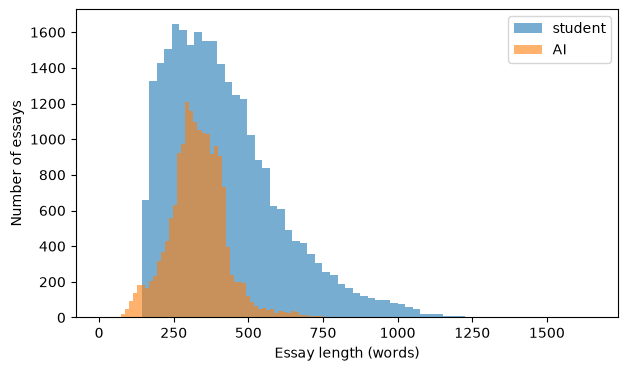

In [5]:
df["n_words"] = df[TEXT_COL].str.split().str.len()
display(df.groupby(LABEL_COL)["n_words"].describe().rename(index={0: "student", 1: "AI"}))

fig, ax = plt.subplots(figsize=(7, 4))
for label, name in [(0, "student"), (1, "AI")]:
    ax.hist(df.loc[df[LABEL_COL] == label, "n_words"], bins=60, alpha=0.6, label=name)
ax.set_xlabel("Essay length (words)")
ax.set_ylabel("Number of essays")
ax.legend()
plt.show()

## How many essays are longer than the models can read?

Transformers read a limited number of *tokens*. A token is a word or a piece of a word,
so an essay has more tokens than words. This cell checks how many essays DistilBERT
(512 tokens) would cut off, and whether 1024 tokens is enough for ModernBERT.

It downloads the two tokenizers the first time. A warning about sequences longer than
512 is expected and harmless here: we only count tokens, we do not run the model.

In [6]:
from transformers import AutoTokenizer

sample = df.sample(2000, random_state=42)
for model_name, limit in [("distilbert-base-uncased", 512), ("answerdotai/ModernBERT-base", 1024)]:
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    n_tokens = sample[TEXT_COL].map(lambda text: len(tokenizer(text)["input_ids"]))
    print(
        f"{model_name}: median {n_tokens.median():.0f} tokens, "
        f"{(n_tokens > limit).mean():.1%} of essays longer than {limit}"
    )

c:\ai-essay-detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\ai-essay-detection\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\47948\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see

distilbert-base-uncased: median 414 tokens, 25.9% of essays longer than 512


c:\ai-essay-detection\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\47948\.cache\huggingface\hub\models--answerdotai--ModernBERT-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


answerdotai/ModernBERT-base: median 419 tokens, 1.7% of essays longer than 1024


## Read a few essays

In [7]:
for label, name in [(0, "STUDENT"), (1, "AI")]:
    essay = df[df[LABEL_COL] == label].sample(1, random_state=1).iloc[0]
    print(f"--- {name} essay, topic: {essay[TOPIC_COL]} ---")
    print(essay[TEXT_COL][:1500], "\n")

--- STUDENT essay, topic: Distance learning ---
Some student can take classes at home because they could find a subject of course that like. Learning websites can help them get better at what they do. It could benefit because they it would seem easier to go on different classes or to take a video to study a subject. For example, taking classes online would give you a head start. Many other schools have students at home take taking these course and have them apply for it. It is like a benefit for them to take some opportunity to get taught about something they have learn or to have a different way of learning it.

I will think they would able to do this if they are interested. For example, Home-schooling could that much money. There could be some reasons for them.

1. They want to try out some different learning strategies.

2. They can apply online.

3. They can try taking some subjects that they like.

In conclusion, it could be able to work for the home-schoolers to also have an educ

## Notes for the report

Fill these in as you go:

- Essays after cleaning:
- Share of AI essays:
- Test topics in the topic split (see `results/splits/split_summary.json`):
- Length difference between student and AI essays:
- Share of essays cut off at 512 tokens: